# Pittsburgh Bridges: Number of Bridges by Neighborhood
## Cami's metric

### Introduction
For my individual project, I will investigate the distribution of bridges across Pittsburgh neighborhoods. I want to compare the number of bridges located in different neighborhoods to determine which areas have the most bridges and how bridge infrastructure is distributed throughout the city.

### Metric
My individual metric is the **Number of Bridges** in each neighborhood. I will count the bridge records assigned to each neighborhood and compare the totals to identify which neighborhoods have the most bridges. This will help show how bridge infrastructure is distributed across Pittsburgh.

### Dataset
I will use the [Pittsburgh Bridges dataset](https://data.wprdc.org/dataset/city-of-pittsburgh-bridges/resource/23f675e5-f745-49c1-8fa0-c5bc35c25184)  from the Western Pennsylvania Regional Data Center (WPRDC).

This dataset contains information about bridges throughout Pittsburgh. It includes details such as the bridge name, starting neighborhood, ending neighborhood, year built, year rehabilitated, and geographic location. I will use the neighborhood column to group and count bridges in each neighborhood. This information will allow me to compare bridge distribution across Pittsburgh and identify the neighborhoods with the highest number of bridges.

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('Data/Bridges.csv')

In [14]:
neighborhoods = df['neighborhood'].dropna().unique().tolist()

In [25]:
col = "neighborhood"
lookup = {n.strip().lower() for n in neighborhoods}
cleaned = df[col].astype(str).str.strip().str.lower()
bridge_counts = (
    cleaned[cleaned.isin(lookup)]
    .value_counts()
    .reindex([n.strip().lower() for n in neighborhoods], fill_value=0)
)

In [26]:
top5 = bridge_counts.nlargest(5, keep="first").reset_index()
top5.columns = ["Neighborhood", "Bridge Count"]
top5["Neighborhood"] = top5["Neighborhood"].str.title()
top5.index = range(1, len(top5) + 1)
top5.index.name = "Rank"
top5

,Neighborhood,Bridge Count
Rank,,
1,Squirrel Hill South,14
2,Central Business District,12
3,Troy Hill,7
4,Overbrook,6
5,Hays,6


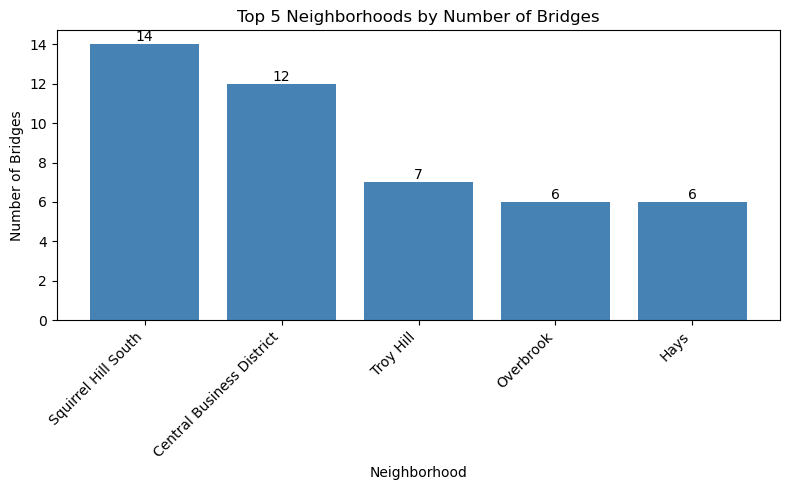

In [23]:
plt.figure(figsize=(8, 5))
plt.bar(top5["Neighborhood"], top5["Bridge Count"], color="steelblue")
for i, v in enumerate(top5["Bridge Count"]):
    plt.text(i, v, str(v), ha="center", va="bottom")
plt.title("Top 5 Neighborhoods by Number of Bridges")
plt.xlabel("Neighborhood")
plt.ylabel("Number of Bridges")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()